In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from pyPLUTO.pload import pload
import warnings
warnings.filterwarnings("ignore", category=ResourceWarning)
warnings.filterwarnings("ignore", category=UserWarning)


PyPLUTO version: 1.2.6   session: Jupyter notebook or qtconsole


In [46]:
# =================================================
# GRAFICAR IMGS INDIVIDUALES Y PÁNELES EN CADA .dbl
# =================================================


# ---------------- Configuración ----------------
W_DIR      = './'
OUT_DIR    = 'plots'
MERIDIONAL = False          # False: ejes (r, θ) | True: plano meridional
XLIM       = None           # p. ej. (1, 8) (solo si MERIDIONAL=False)
LOG_VARS   = {'rho', 'prs'}
DPI        = 150

# Figura combinada (3 filas x 2 columnas)
PANEL_VARS    = ['rho', 'prs', 'vx1', 'vx2', 'bx1', 'bx2', 'vx3', 'tr1']   
PANEL_NCOLS   = 2
PANEL_FIGSIZE = (12, 12)
PANEL_DPI     = 200
FS_LABEL, FS_TICK, FS_TITLE = 16, 14, 16   

LABELS = {
    'rho': r'$\rho$',   'prs': r'$p$',
    'vx1': r'$v_r$',    'vx2': r'$v_\theta$',   'vx3': r'$v_\phi$',
    'bx1': r'$B_r$',    'bx2': r'$B_\theta$',   'bx3': r'$B_\phi$',
    'tr1': 'tr1',
}
# ------------------------------------------------

def get_norm(var, data):
    vmin, vmax = np.nanmin(data), np.nanmax(data)
    if var.lower() in LOG_VARS and vmin > 0 and vmax > vmin:
        return LogNorm(vmin, vmax), 'viridis'
    if vmin < 0 < vmax:
        lim = max(abs(vmin), abs(vmax))
        return Normalize(-lim, lim), 'RdBu_r'
    if vmin == vmax:
        vmin, vmax = vmin - 0.5, vmax + 0.5
    return Normalize(vmin, vmax), 'viridis'

def draw_panel(fig, ax, X, Y, data, var, fs_label=None, fs_tick=None, show_labels=True):
    norm, cmap = get_norm(var, data)
    pcm = ax.pcolormesh(X, Y, data, shading='auto', norm=norm, cmap=cmap)
    label = LABELS.get(var.lower(), var)
    cb = fig.colorbar(pcm, ax=ax)
    cb.set_label(label, fontsize=fs_label)
    if MERIDIONAL:
        if show_labels:
            ax.set_xlabel(r'$R = r\sin\theta$', fontsize=fs_label)
            ax.set_ylabel(r'$z = r\cos\theta$', fontsize=fs_label)
        ax.set_aspect('equal')
    else:
        if show_labels:
            ax.set_xlabel(r'$r\ [R_*]$', fontsize=fs_label)
            ax.set_ylabel(r'$\theta$ [rad]', fontsize=fs_label)
        if XLIM:
            ax.set_xlim(*XLIM)
    if fs_tick:
        ax.tick_params(labelsize=fs_tick)
        cb.ax.tick_params(labelsize=fs_tick)

    return label

def get_data(D, var, shape):
    data = np.squeeze(np.asarray(getattr(D, var)))
    return data.T if data.shape != shape else data

# Pasos disponibles: primera columna de dbl.out
with open(os.path.join(W_DIR, 'dbl.out')) as f:
    steps = [int(line.split()[0]) for line in f if line.strip()]

for ns in steps:
    D = pload(ns, w_dir=W_DIR)
    step_dir = os.path.join(OUT_DIR, f'step_{ns:04d}')
    os.makedirs(step_dir, exist_ok=True)

    R, TH = np.meshgrid(D.x1, D.x2, indexing='ij')
    X, Y = (R * np.sin(TH), R * np.cos(TH)) if MERIDIONAL else (R, TH)

    # ---------- Imágenes individuales ----------
    for var in D.vars:
        data = get_data(D, var, R.shape)
        fig, ax = plt.subplots(figsize=(7, 6) if MERIDIONAL else (9, 4.5))
        draw_panel(fig, ax, X, Y, data, var)
        ax.set_title(f'{var} | paso {ns} | t = {D.SimTime:.4g}')
        fig.tight_layout()
        fig.savefig(os.path.join(step_dir, f'{var}.png'), dpi=DPI)
        plt.close(fig)

    # ---------- Figura combinada (4x2) ----------
    available = {v.lower(): v for v in D.vars}   
    selected = [available[v] for v in PANEL_VARS if v in available]
    nrows = -(-len(selected) // PANEL_NCOLS)

    fig, axes = plt.subplots(nrows, PANEL_NCOLS, figsize=PANEL_FIGSIZE,
                             sharex=True, sharey=True,
                             layout='constrained', squeeze=False)
    for ax, var in zip(axes.flat, selected):
        data = get_data(D, var, R.shape)
        label = draw_panel(fig, ax, X, Y, data, var, FS_LABEL, FS_TICK, show_labels=False)
        ax.set_title(label, fontsize=FS_TITLE)
    for ax in axes.flat[len(selected):]:
        ax.axis('off')

    if MERIDIONAL:
        fig.supxlabel(r'$R = r\sin\theta$', fontsize=FS_LABEL)
        fig.supylabel(r'$z = r\cos\theta$', fontsize=FS_LABEL)
    else:
        fig.supxlabel(r'$r\ [R_*]$', fontsize=FS_LABEL)
        fig.supylabel(r'$\theta$ [rad]', fontsize=FS_LABEL)

    fig.suptitle(f'Paso {ns},  $t = {D.SimTime:.4g}$', fontsize=FS_TITLE + 2)
    fig.savefig(os.path.join(step_dir, 'panel.png'), dpi=PANEL_DPI)
    fig.savefig(os.path.join(step_dir, 'panel.pdf'), dpi=PANEL_DPI)
    plt.close(fig)

    print(f'Paso {ns} listo -> {step_dir}')

Reading single data file : ./data.0000.dbl
Paso 0 listo -> plots/step_0000
Reading single data file : ./data.0001.dbl
Paso 1 listo -> plots/step_0001
Reading single data file : ./data.0002.dbl
Paso 2 listo -> plots/step_0002
Reading single data file : ./data.0003.dbl
Paso 3 listo -> plots/step_0003
Reading single data file : ./data.0004.dbl
Paso 4 listo -> plots/step_0004
Reading single data file : ./data.0005.dbl
Paso 5 listo -> plots/step_0005
Reading single data file : ./data.0006.dbl
Paso 6 listo -> plots/step_0006
Reading single data file : ./data.0007.dbl
Paso 7 listo -> plots/step_0007
Reading single data file : ./data.0008.dbl
Paso 8 listo -> plots/step_0008
Reading single data file : ./data.0009.dbl
Paso 9 listo -> plots/step_0009
Reading single data file : ./data.0010.dbl
Paso 10 listo -> plots/step_0010
Reading single data file : ./data.0011.dbl
Paso 11 listo -> plots/step_0011
Reading single data file : ./data.0012.dbl
Paso 12 listo -> plots/step_0012
Reading single data fi

In [9]:
# =================================================
# HACER ANIMACIÓN PARA ALGUNA DE LAS VARIABLES
# =================================================


from matplotlib.animation import FuncAnimation, PillowWriter, FFMpegWriter

# ---------------- Configuración ----------------
W_DIR   = './'
VAR     = 'tr1'        
LOG     = False         # True para rho y prs
SIGNED  = True      # True para variables con signo (Bx1, vx2, ...) 
FPS     = 5
OUTFILE = f'{VAR}.gif'   
OUT_DIR = 'plots/anim'
DPI     = 150
# ------------------------------------------------

with open(os.path.join(W_DIR, 'dbl.out')) as f:
    steps = [int(l.split()[0]) for l in f if l.strip()]

frames, times = [], []
for ns in steps:
    D = pload(ns, w_dir=W_DIR)
    data = np.squeeze(np.asarray(getattr(D, VAR)))
    if ns == steps[0]:
        x1, x2 = D.x1, D.x2
        if data.shape != (len(x1), len(x2)):
            transpose = True
        else:
            transpose = False
    frames.append(data.T if transpose else data)
    times.append(D.SimTime)

allv = np.stack(frames)
vmin, vmax = np.nanmin(allv), np.nanmax(allv)

if LOG:
    norm, cmap = LogNorm(vmin, vmax), 'viridis'
elif SIGNED:
    lim = max(abs(vmin), abs(vmax))
    norm, cmap = Normalize(-lim, lim), 'RdBu_r'
else:
    norm, cmap = Normalize(vmin, vmax), 'viridis'

R, TH = np.meshgrid(x1, x2, indexing='ij')

fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
pcm = ax.pcolormesh(R, TH, frames[0], shading='auto', norm=norm, cmap=cmap)
fig.colorbar(pcm, ax=ax, label=VAR)
ax.set_xlabel(r'$r\ [R_*]$'); ax.set_ylabel(r'$\theta$ [rad]')
title = ax.set_title('')

def update(i):
    pcm.set_array(frames[i].ravel())
    title.set_text(f'{VAR} | paso {steps[i]} | t = {times[i]:.4g}')
    return pcm, title

anim = FuncAnimation(fig, update, frames=len(frames), blit=False)

writer = PillowWriter(fps=FPS) if OUTFILE.endswith('.gif') else FFMpegWriter(fps=FPS)
os.makedirs(OUT_DIR, exist_ok=True)
anim.save(os.path.join(OUT_DIR, OUTFILE), writer=writer, dpi=DPI)
plt.close(fig)
print('Guardado:', OUTFILE)

Reading single data file : ./data.0000.dbl
Reading single data file : ./data.0001.dbl
Reading single data file : ./data.0002.dbl
Reading single data file : ./data.0003.dbl
Reading single data file : ./data.0004.dbl
Reading single data file : ./data.0005.dbl
Reading single data file : ./data.0006.dbl
Reading single data file : ./data.0007.dbl
Reading single data file : ./data.0008.dbl
Reading single data file : ./data.0009.dbl
Reading single data file : ./data.0010.dbl
Reading single data file : ./data.0011.dbl
Reading single data file : ./data.0012.dbl
Reading single data file : ./data.0013.dbl
Reading single data file : ./data.0014.dbl
Reading single data file : ./data.0015.dbl
Reading single data file : ./data.0016.dbl
Reading single data file : ./data.0017.dbl
Reading single data file : ./data.0018.dbl
Reading single data file : ./data.0019.dbl
Reading single data file : ./data.0020.dbl
Guardado: tr1.gif


In [6]:
steps

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]

Reading single data file : ./data.0000.dbl


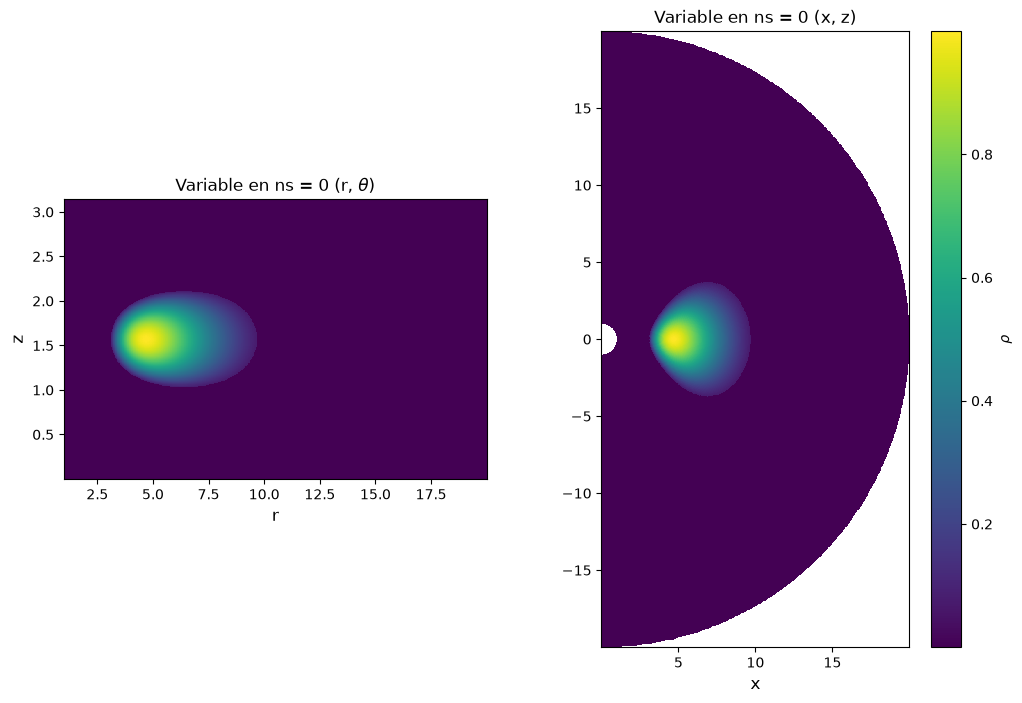

In [42]:
# =================================================
# GRAFICAR IMG Y VAR INDIVIDUAL
# =================================================

step = 0

D = pload(step, w_dir='./')        
var  = D.rho
r, th = D.x1, D.x2          
R, T = np.meshgrid(r, th, indexing='ij')
X, Z = R*np.sin(T), R*np.cos(T)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 8))
 
im1 = ax1.pcolormesh(R, T, var, shading='auto')
ax1.set_title(fr'Variable en ns = {step} (r, $\theta$)', fontsize=12)
ax1.set_xlabel('r', fontsize=12); ax1.set_ylabel(r'$\theta$', fontsize=12)

im2 = ax2.pcolormesh(X, Z, var, shading='auto')
fig.colorbar(im2, ax=ax2, label=r'$\rho$')
ax2.set_title(fr'Variable en ns = {step} (x, z)', fontsize=12)
ax2.set_xlabel('x', fontsize=12); ax1.set_ylabel('z', fontsize=12)

ax1.set_aspect(4); ax2.set_aspect('equal', adjustable='box')